# CC3074 - Modelización y Simulación
## Laboratorio — A\*, Hill Climbing y Optimización de Redes

Diego López — 23747
Universidad del Valle de Guatemala, 2026

## Utilidades comunes

Funciones reutilizadas en las tres partes: grafos no dirigidos, tramos de una ruta, reconstrucción de caminos, tablas por iteración y gráficas de redes.

In [1]:
import heapq
import itertools
import math
import random
from collections import Counter, deque

import matplotlib.pyplot as plt

In [2]:
def grafo_no_dirigido(aristas):
    # lista de (u, v, peso) -> dict de adyacencia en los dos sentidos
    grafo = {}
    for u, v, peso in aristas:
        grafo.setdefault(u, {})[v] = peso
        grafo.setdefault(v, {})[u] = peso
    return grafo


def pares(ruta):
    # [a, b, c] -> [(a, b), (b, c)]
    return list(zip(ruta, ruta[1:]))


def fmt_ruta(ruta):
    return "-".join(map(str, ruta))


def reconstruir_ruta(padre, destino):
    # se camina para atras hasta llegar al nodo sin padre
    ruta = []
    nodo = destino
    while nodo is not None:
        ruta.append(nodo)
        nodo = padre[nodo]
    return ruta[::-1]


def imprimir_tabla(encabezados, filas):
    filas = [[str(c) for c in fila] for fila in filas]
    anchos = [max([len(e)] + [len(f[i]) for f in filas]) for i, e in enumerate(encabezados)]

    def linea(celdas):
        return " | ".join(c.ljust(a) for c, a in zip(celdas, anchos))

    print(linea(encabezados))
    print("-+-".join("-" * a for a in anchos))
    for fila in filas:
        print(linea(fila))


def dibujar_grafo(pos, aristas, ruta, titulo):
    # todas las aristas en gris y la ruta encima en rojo
    tramos_ruta = {frozenset(t) for t in pares(ruta)}
    _, ax = plt.subplots(figsize=(8, 5))
    for u, v, peso in aristas:
        en_ruta = frozenset((u, v)) in tramos_ruta
        (x1, y1), (x2, y2) = pos[u], pos[v]
        ax.plot([x1, x2], [y1, y2], color="crimson" if en_ruta else "lightgray",
                lw=3 if en_ruta else 1.5, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(peso), fontsize=9, ha="center", va="center",
                bbox=dict(fc="white", ec="none", pad=0.5), zorder=2)
    for nodo, (x, y) in pos.items():
        ax.scatter(x, y, s=600, color="steelblue", zorder=3)
        ax.text(x, y, str(nodo), color="white", ha="center", va="center", fontweight="bold", zorder=4)
    ax.set_title(titulo)
    ax.axis("off")
    plt.show()

# Parte 1. Hill Climbing - Problema del agente viajero

### Enunciado

Un vendedor vive en la ciudad 1. Debe visitar las ciudades 2 a 7 exactamente una vez y regresar a la ciudad 1. No todas las ciudades están conectadas directamente. El objetivo es encontrar un recorrido válido con la menor distancia total posible.

| Ciudad | Ciudad | Distancia |
|---|---|---|
| 1 | 2 | 12 |
| 1 | 3 | 10 |
| 1 | 7 | 12 |
| 2 | 3 | 8 |
| 2 | 4 | 12 |
| 3 | 4 | 11 |
| 3 | 5 | 3 |
| 3 | 7 | 9 |
| 4 | 5 | 11 |
| 4 | 6 | 10 |
| 5 | 6 | 6 |
| 5 | 7 | 7 |
| 6 | 7 | 9 |

### Modelo para Hill Climbing

Solución: un tour que inicia y termina en la ciudad 1. Función objetivo: distancia total del tour; se desea minimizar. Vecino: tour obtenido al invertir un sub-recorrido. Un vecino es inválido si utiliza una carretera inexistente.

### Entradas

In [3]:
CARRETERAS = [
    (1, 2, 12), (1, 3, 10), (1, 7, 12), (2, 3, 8), (2, 4, 12), (3, 4, 11), (3, 5, 3),
    (3, 7, 9), (4, 5, 11), (4, 6, 10), (5, 6, 6), (5, 7, 7), (6, 7, 9),
]
DISTANCIAS = grafo_no_dirigido(CARRETERAS)
CIUDAD_BASE = 1
TOUR_INICIAL = [1, 2, 3, 4, 5, 6, 7, 1]

### Actividades

> 1. Implemente distancia_tour(tour). Debe devolver la distancia total o indicar que el tour no es válido. Verifique el tour inicial 1-2-3-4-5-6-7-1.

Un tour es válido si empieza y termina en la misma ciudad, visita cada ciudad una vez y solo usa carreteras existentes. Si no es válido devuelve `None`.

In [4]:
def distancia_tour(tour, distancias):
    # none = tour invalido (no cierra, repite/falta ciudad o usa carretera inexistente)
    if tour[0] != tour[-1] or sorted(tour[:-1]) != sorted(distancias):
        return None
    total = 0
    for u, v in pares(tour):
        if v not in distancias[u]:
            return None
        total += distancias[u][v]
    return total


print(f"tour inicial {fmt_ruta(TOUR_INICIAL)} -> distancia {distancia_tour(TOUR_INICIAL, DISTANCIAS)}")

tour_invalido = [1, 2, 5, 3, 4, 6, 7, 1]
print(f"tour {fmt_ruta(tour_invalido)} -> {distancia_tour(tour_invalido, DISTANCIAS)} (no existe la carretera 2-5)")

tour inicial 1-2-3-4-5-6-7-1 -> distancia 69
tour 1-2-5-3-4-6-7-1 -> None (no existe la carretera 2-5)


> 2. Implemente vecinos(tour), generando tours mediante inversión de un sub-recorrido. La ciudad 1 debe permanecer fija.

Se invierte `tour[i..j]` para cada par 1 ≤ i < j ≤ n−2, así la primera y la última posición (ciudad 1) no se mueven. Solo se devuelven los vecinos válidos.

In [5]:
def vecinos(tour, distancias):
    # 2-opt: se invierte tour[i..j]; i arranca en 1 y j llega a n-2 para que la ciudad base no se mueva
    resultado = []
    for i in range(1, len(tour) - 2):
        for j in range(i + 1, len(tour) - 1):
            vecino = tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]
            distancia = distancia_tour(vecino, distancias)
            if distancia is not None:
                resultado.append((vecino, distancia, tour[i:j + 1]))
    return resultado


vecinos_iniciales = vecinos(TOUR_INICIAL, DISTANCIAS)
print(f"vecinos validos del tour inicial: {len(vecinos_iniciales)}\n")
imprimir_tabla(
    ["tramo invertido", "vecino", "distancia"],
    [(fmt_ruta(tramo), fmt_ruta(v), d) for v, d, tramo in vecinos_iniciales],
)

vecinos validos del tour inicial: 5

tramo invertido | vecino          | distancia
----------------+-----------------+----------
2-3             | 1-3-2-4-5-6-7-1 | 68       
2-3-4-5-6-7     | 1-7-6-5-4-3-2-1 | 69       
3-4             | 1-2-4-3-5-6-7-1 | 65       
4-5             | 1-2-3-5-4-6-7-1 | 65       
5-6             | 1-2-3-4-6-5-7-1 | 66       


> 3. Implemente Hill Climbing de máximo descenso: evalúe todos los vecinos válidos y muévase al de menor distancia. Deténgase cuando ninguno mejore el tour actual.
>
> 4. En cada iteración muestre: iteración, tour actual, distancia, mejor vecino, distancia del vecino y tramo invertido.

En cada iteración se toma el vecino válido de menor distancia. Si mejora al actual se acepta; si no, el algoritmo se detiene. La última fila muestra el vecino que ya no mejoró.

In [6]:
def hill_climbing(tour_inicial, distancias):
    actual = tour_inicial
    dist_actual = distancia_tour(actual, distancias)
    if dist_actual is None:
        raise ValueError(f"tour inicial invalido: {fmt_ruta(actual)}")

    registro = []
    while True:
        # nunca queda vacio: invertir todo el recorrido siempre es valido
        mejor, dist_mejor, tramo = min(vecinos(actual, distancias), key=lambda c: c[1])
        mejora = dist_mejor < dist_actual
        registro.append((len(registro) + 1, fmt_ruta(actual), dist_actual,
                         fmt_ruta(mejor), dist_mejor, fmt_ruta(tramo), "si" if mejora else "no"))
        if not mejora:
            return actual, dist_actual, registro
        actual, dist_actual = mejor, dist_mejor

In [7]:
tour_hc, dist_hc, registro_hc = hill_climbing(TOUR_INICIAL, DISTANCIAS)
imprimir_tabla(
    ["iter", "tour actual", "dist", "mejor vecino", "dist vecino", "tramo invertido", "mejora"],
    registro_hc,
)
print(f"\nresultado: {fmt_ruta(tour_hc)} con distancia {dist_hc}")

iter | tour actual     | dist | mejor vecino    | dist vecino | tramo invertido | mejora
-----+-----------------+------+-----------------+-------------+-----------------+-------
1    | 1-2-3-4-5-6-7-1 | 69   | 1-2-4-3-5-6-7-1 | 65          | 3-4             | si    
2    | 1-2-4-3-5-6-7-1 | 65   | 1-2-4-6-5-3-7-1 | 64          | 3-5-6           | si    
3    | 1-2-4-6-5-3-7-1 | 64   | 1-7-3-5-6-4-2-1 | 64          | 2-4-6-5-3-7     | no    

resultado: 1-2-4-6-5-3-7-1 con distancia 64


> 5. Implemente una variante con reinicios aleatorios. Ejecute 100 reinicios con semilla fija y reporte el mejor tour encontrado y su distancia.

Cada reinicio parte de un tour aleatorio válido (se baraja hasta que solo use carreteras existentes) y aplica el mismo Hill Climbing. Semilla: 42.

In [8]:
def tour_aleatorio_valido(distancias, base, rng):
    # se baraja hasta que salga uno que use solo carreteras existentes
    resto = [c for c in distancias if c != base]
    while True:
        rng.shuffle(resto)
        tour = [base, *resto, base]
        if distancia_tour(tour, distancias) is not None:
            return tour


def hill_climbing_reinicios(distancias, base, n_reinicios, semilla):
    rng = random.Random(semilla)
    resultados = []
    for _ in range(n_reinicios):
        inicial = tour_aleatorio_valido(distancias, base, rng)
        tour, distancia, _ = hill_climbing(inicial, distancias)
        resultados.append((inicial, tour, distancia))
    return resultados

In [9]:
N_REINICIOS = 100
SEMILLA = 42

resultados = hill_climbing_reinicios(DISTANCIAS, CIUDAD_BASE, N_REINICIOS, SEMILLA)
_, mejor_tour, mejor_dist = min(resultados, key=lambda r: r[2])

print("distancia final de cada reinicio (cuantas veces se llego a cada optimo local):\n")
frecuencias = Counter(d for _, _, d in resultados)
imprimir_tabla(["distancia final", "reinicios"], sorted(frecuencias.items()))

print(f"\nmejor tour encontrado: {fmt_ruta(mejor_tour)} con distancia {mejor_dist}")

distancia final de cada reinicio (cuantas veces se llego a cada optimo local):

distancia final | reinicios
----------------+----------
63              | 36       
64              | 21       
65              | 43       

mejor tour encontrado: 1-2-4-6-7-5-3-1 con distancia 63


> 6. Genere una gráfica del mejor recorrido encontrado y explique por qué Hill Climbing puede detenerse en una solución local.

El PDF no da coordenadas, así que las ciudades se colocan en un círculo. En gris están todas las carreteras y en rojo el mejor tour.

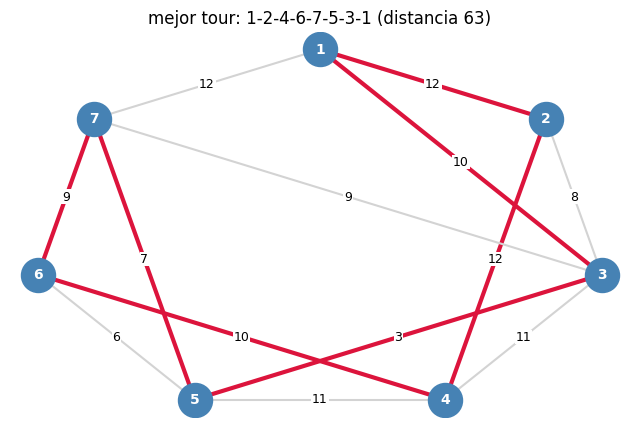

In [10]:
def layout_circular(nodos):
    paso = 2 * math.pi / len(nodos)
    return {n: (math.cos(math.pi / 2 - k * paso), math.sin(math.pi / 2 - k * paso))
            for k, n in enumerate(nodos)}


dibujar_grafo(layout_circular(sorted(DISTANCIAS)), CARRETERAS, mejor_tour,
              f"mejor tour: {fmt_ruta(mejor_tour)} (distancia {mejor_dist})")

Hill Climbing se detiene cuando ningún vecino mejora el tour actual. Ese tour es el mejor de su vecindario (óptimo local), pero no necesariamente el mejor de todos. Desde el tour inicial se detuvo en 64. La búsqueda exhaustiva de abajo (720 permutaciones) confirma que el óptimo global es 63.

In [11]:
validos = [
    (d, t) for p in itertools.permutations([c for c in DISTANCIAS if c != CIUDAD_BASE])
    if (d := distancia_tour(t := [CIUDAD_BASE, *p, CIUDAD_BASE], DISTANCIAS)) is not None
]
optimo_global = min(d for d, _ in validos)
print(f"tours validos: {len(validos)} de 720")
print(f"optimo global: {optimo_global} -> {[fmt_ruta(t) for d, t in validos if d == optimo_global]}")
assert mejor_dist == optimo_global

tours validos: 20 de 720
optimo global: 63 -> ['1-2-4-6-7-5-3-1', '1-3-5-7-6-4-2-1']


### Preguntas de análisis

> ¿Qué representa una solución, un vecino y la función objetivo en este problema?

- Solución: un tour que sale de la ciudad 1, visita las ciudades 2 a 7 una sola vez y regresa a la 1.
- Vecino: el tour que resulta de invertir un sub-recorrido del tour actual sin mover la ciudad 1. Es inválido si usa una carretera inexistente.
- Función objetivo: la distancia total del tour. Se minimiza.

> ¿Por qué Hill Climbing puede detenerse aunque exista un recorrido mejor?

Porque solo compara el tour actual contra sus vecinos y se detiene cuando ninguno lo mejora (óptimo local). No acepta movimientos que empeoren, así que no llega a soluciones que requieren varios cambios. Ejemplo: desde `1-2-3-4-5-6-7-1` se detuvo en `1-2-4-6-5-3-7-1` (64), pero existe `1-2-4-6-7-5-3-1` (63).

> ¿Qué efecto tuvieron los reinicios aleatorios?

Cada reinicio parte de un tour distinto y termina en un óptimo local distinto. Con 100 reinicios (semilla 42) los resultados fueron 65 (43 veces), 64 (21 veces) y 63 (36 veces). El mejor, 63, coincide con el óptimo global.

# Parte 2. A\* - Ruta más corta en una red

### Enunciado

Un guardabosques debe desplazarse desde la entrada O hasta el punto T. Las estaciones O, A, B, C, D, E y T están conectadas por caminos de doble sentido. Se desea encontrar una ruta de costo mínimo utilizando A\*.

| Camino | Distancia |
|---|---|
| O-A | 2 |
| O-B | 5 |
| O-C | 4 |
| A-B | 2 |
| A-D | 7 |
| B-C | 1 |
| B-D | 4 |
| B-E | 3 |
| C-E | 4 |
| D-E | 1 |
| D-T | 5 |
| E-T | 7 |

Coordenadas para calcular la heurística euclidiana:

| Estación | x | y |
|---|---|---|
| O | 0.0 | 0.0 |
| A | 1.5 | 1.2 |
| B | 2.5 | 0.0 |
| C | 2.8 | -0.8 |
| D | 5.5 | 1.0 |
| E | 5.2 | 0.2 |
| T | 9.0 | 0.5 |

### Recordatorio

A\* selecciona el nodo con menor f(n) = g(n) + h(n). g(n) es el costo acumulado desde el origen; h(n) es una estimación del costo restante; f(n) es el costo total estimado.

### Entradas

In [12]:
CAMINOS = [
    ("O", "A", 2), ("O", "B", 5), ("O", "C", 4), ("A", "B", 2), ("A", "D", 7), ("B", "C", 1),
    ("B", "D", 4), ("B", "E", 3), ("C", "E", 4), ("D", "E", 1), ("D", "T", 5), ("E", "T", 7),
]
GRAFO_RED = grafo_no_dirigido(CAMINOS)
COORDENADAS = {
    "O": (0.0, 0.0), "A": (1.5, 1.2), "B": (2.5, 0.0), "C": (2.8, -0.8),
    "D": (5.5, 1.0), "E": (5.2, 0.2), "T": (9.0, 0.5),
}
INICIO, META = "O", "T"

### Actividades

> 7. Implemente una función heuristica(nodo, meta, coordenadas) usando distancia euclidiana.

h(n) es la distancia en línea recta entre n y T. Se verifica que h(u) ≤ costo(u, v) + h(v) en cada camino, es decir, que es consistente y, por lo tanto, admisible.

In [13]:
def heuristica(nodo, meta, coordenadas):
    return math.dist(coordenadas[nodo], coordenadas[meta])


def heuristica_nula(nodo, meta, coordenadas):
    # con esto a* se porta igual que dijkstra
    return 0


imprimir_tabla(["nodo", f"h(n) hacia {META}"],
               [(n, f"{heuristica(n, META, COORDENADAS):.3f}") for n in COORDENADAS])

# consistencia: h(u) <= costo(u, v) + h(v) en cada camino; si se cumple, a* da el optimo
for u, v, costo in CAMINOS:
    for a, b in ((u, v), (v, u)):
        assert heuristica(a, META, COORDENADAS) <= costo + heuristica(b, META, COORDENADAS), (a, b)
print("\nok: la heuristica es consistente (y por lo tanto admisible)")

nodo | h(n) hacia T
-----+-------------
O    | 9.014       
A    | 7.533       
B    | 6.519       
C    | 6.335       
D    | 3.536       
E    | 3.812       
T    | 0.000       

ok: la heuristica es consistente (y por lo tanto admisible)


> 8. Implemente A\* utilizando heapq. No utilizar networkx para resolver la búsqueda.

- La lista abierta es un heap de tuplas `(f, h, nodo, g)`. Si hay empate en f, gana el de menor h y luego el orden alfabético.
- Las entradas desactualizadas del heap se ignoran al salir.
- La heurística entra como parámetro `h`, para reutilizar la función con h(n)=0.

In [14]:
def lista_abierta(abierta, cerrados, mejor_g):
    # solo las entradas vigentes del heap, ordenadas como las sacaria a*
    vigentes = sorted(e for e in abierta if e[2] not in cerrados and e[3] == mejor_g[e[2]])
    return ", ".join(f"{n}(f={f:.2f})" for f, _, n, _ in vigentes) or "-"


def a_estrella(grafo, coordenadas, inicio, meta, h=heuristica):
    h_inicio = h(inicio, meta, coordenadas)
    abierta = [(h_inicio, h_inicio, inicio, 0)]  # (f, h, nodo, g)
    mejor_g = {inicio: 0}
    padre = {inicio: None}
    cerrados = set()
    registro = []

    while abierta:
        f, h_n, nodo, g = heapq.heappop(abierta)
        if nodo in cerrados:
            continue  # entrada vieja, ese nodo ya se expandio con un g mejor
        cerrados.add(nodo)

        if nodo != meta:
            for vecino, costo in grafo[nodo].items():
                g_nuevo = g + costo
                if vecino not in cerrados and g_nuevo < mejor_g.get(vecino, math.inf):
                    mejor_g[vecino] = g_nuevo
                    padre[vecino] = nodo
                    h_v = h(vecino, meta, coordenadas)
                    heapq.heappush(abierta, (g_nuevo + h_v, h_v, vecino, g_nuevo))

        registro.append((len(registro) + 1, nodo, g, f"{h_n:.2f}", f"{f:.2f}",
                         lista_abierta(abierta, cerrados, mejor_g)))
        if nodo == meta:
            return reconstruir_ruta(padre, meta), g, registro

    return None, math.inf, registro


ENCABEZADOS_A = ["iter", "expandido", "g(n)", "h(n)", "f(n)", "lista abierta (despues de expandir)"]

> 9. En cada iteración muestre: nodo expandido, g(n), h(n), f(n) y contenido de la lista abierta.

La lista abierta se muestra después de expandir cada nodo.

In [15]:
ruta_a, costo_a, registro_a = a_estrella(GRAFO_RED, COORDENADAS, INICIO, META)
imprimir_tabla(ENCABEZADOS_A, registro_a)

iter | expandido | g(n) | h(n) | f(n)  | lista abierta (despues de expandir)
-----+-----------+------+------+-------+------------------------------------
1    | O         | 0    | 9.01 | 9.01  | A(f=9.53), C(f=10.33), B(f=11.52)  
2    | A         | 2    | 7.53 | 9.53  | C(f=10.33), B(f=10.52), D(f=12.54) 
3    | C         | 4    | 6.33 | 10.33 | B(f=10.52), E(f=11.81), D(f=12.54) 
4    | B         | 4    | 6.52 | 10.52 | E(f=10.81), D(f=11.54)             
5    | E         | 7    | 3.81 | 10.81 | D(f=11.54), T(f=14.00)             
6    | D         | 8    | 3.54 | 11.54 | T(f=13.00)                         
7    | T         | 13   | 0.00 | 13.00 | -                                  


> 10. Encuentre la ruta de O a T, muestre el camino final y su costo total.

In [16]:
print(f"camino final: {fmt_ruta(ruta_a)}")
print(f"costo total: {costo_a}")

camino final: O-A-B-D-T
costo total: 13


> 11. Ejecute nuevamente el algoritmo utilizando h(n)=0. Compare el resultado con A\* y explique la relación con Dijkstra.

In [17]:
ruta_0, costo_0, registro_0 = a_estrella(GRAFO_RED, COORDENADAS, INICIO, META, h=heuristica_nula)
imprimir_tabla(ENCABEZADOS_A, registro_0)

print("\ncomparacion:\n")
imprimir_tabla(
    ["variante", "ruta", "costo", "nodos expandidos", "orden de expansion"],
    [
        ("A* (euclidiana)", fmt_ruta(ruta_a), costo_a, len(registro_a), fmt_ruta([r[1] for r in registro_a])),
        ("h(n)=0 (Dijkstra)", fmt_ruta(ruta_0), costo_0, len(registro_0), fmt_ruta([r[1] for r in registro_0])),
    ],
)

iter | expandido | g(n) | h(n) | f(n)  | lista abierta (despues de expandir)
-----+-----------+------+------+-------+------------------------------------
1    | O         | 0    | 0.00 | 0.00  | A(f=2.00), C(f=4.00), B(f=5.00)    
2    | A         | 2    | 0.00 | 2.00  | B(f=4.00), C(f=4.00), D(f=9.00)    
3    | B         | 4    | 0.00 | 4.00  | C(f=4.00), E(f=7.00), D(f=8.00)    
4    | C         | 4    | 0.00 | 4.00  | E(f=7.00), D(f=8.00)               
5    | E         | 7    | 0.00 | 7.00  | D(f=8.00), T(f=14.00)              
6    | D         | 8    | 0.00 | 8.00  | T(f=13.00)                         
7    | T         | 13   | 0.00 | 13.00 | -                                  

comparacion:

variante          | ruta      | costo | nodos expandidos | orden de expansion
------------------+-----------+-------+------------------+-------------------
A* (euclidiana)   | O-A-B-D-T | 13    | 7                | O-A-C-B-E-D-T     
h(n)=0 (Dijkstra) | O-A-B-D-T | 13    | 7                |

- Ambas encuentran `O-A-B-D-T` con costo 13. Existe otra ruta empatada de costo 13, `O-A-B-E-D-T`. Se devuelve la primera porque D se alcanza desde B con g = 8 y pasar por E no lo mejora.
- Con h(n)=0 se tiene f(n) = g(n): los nodos se expanden por costo acumulado, que es exactamente el algoritmo de Dijkstra.
- Ambas expanden 7 nodos y solo cambia el orden (A\* expande C antes que B). No hay ahorro porque A\* debe expandir todo nodo con f(n) menor al costo óptimo (13), y aquí todos cumplen eso (el mayor es D con f = 11.54).

> 12. Grafique la red con matplotlib y resalte la ruta encontrada.

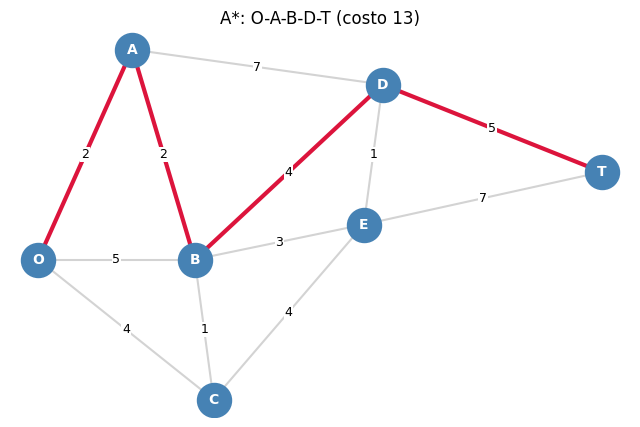

In [18]:
dibujar_grafo(COORDENADAS, CAMINOS, ruta_a, f"A*: {fmt_ruta(ruta_a)} (costo {costo_a})")

### Preguntas de análisis

> ¿Qué información aporta g(n)? ¿Qué información aporta h(n)?

- g(n): costo real acumulado desde O hasta n.
- h(n): estimación del costo restante desde n hasta T. Aquí es la distancia euclidiana, que no sobreestima el costo real (admisible y consistente, verificado por código).

> ¿Por qué una heurística útil puede reducir la cantidad de nodos explorados?

Porque los nodos lejanos a la meta tienen h(n) alta y, por lo tanto, f(n) alta. Los que tienen f(n) mayor que el costo óptimo nunca se expanden. Mientras más se acerque h(n) al costo real sin pasarse, menos nodos se exploran. En esta red no hubo ahorro porque todos los nodos tienen f(n) < 13, pero sí cambió el orden de expansión.

> ¿Qué ocurre conceptualmente cuando h(n)=0?

f(n) = g(n): el algoritmo elige solo por costo acumulado y A\* se convierte en Dijkstra. Sigue encontrando la ruta óptima, pero expande en todas las direcciones sin orientarse hacia la meta.

# Parte 3. Flujo Máximo y Costo Mínimo - Distribución de suministros

### Enunciado

Un centro de distribución S debe enviar suministros hacia un centro de atención T. Los nodos A, B, C, D y E representan centros intermedios. Cada conexión tiene una capacidad máxima y un costo por unidad transportada.

Las capacidades conservan la red del laboratorio base. Para incorporar el tema de Costo Mínimo, en esta versión se agregan costos unitarios didácticos a cada conexión.

| Tramo | Capacidad | Costo/unidad |
|---|---|---|
| S → A | 5 | 2 |
| S → B | 7 | 1 |
| S → C | 4 | 3 |
| A → B | 1 | 1 |
| A → D | 3 | 2 |
| B → C | 2 | 1 |
| B → D | 4 | 3 |
| B → E | 5 | 2 |
| C → E | 4 | 1 |
| D → T | 9 | 2 |
| E → D | 1 | 1 |
| E → T | 6 | 3 |

### Entradas

In [19]:
TRAMOS = [  # (origen, destino, capacidad, costo por unidad)
    ("S", "A", 5, 2), ("S", "B", 7, 1), ("S", "C", 4, 3), ("A", "B", 1, 1),
    ("A", "D", 3, 2), ("B", "C", 2, 1), ("B", "D", 4, 3), ("B", "E", 5, 2),
    ("C", "E", 4, 1), ("D", "T", 9, 2), ("E", "D", 1, 1), ("E", "T", 6, 3),
]
CAPACIDADES = {(u, v): cap for u, v, cap, _ in TRAMOS}
COSTOS = {(u, v): costo for u, v, _, costo in TRAMOS}
FUENTE, DESTINO = "S", "T"

## Parte A - Flujo Máximo

> 13. Construya la red residual incluyendo aristas de regreso con capacidad inicial 0.

Por cada tramo u→v con capacidad c se crea u→v = c y la arista de regreso v→u = 0.

In [20]:
def construir_residual(capacidades):
    # cada tramo trae su arista de regreso arrancando en 0
    residual = {}
    for (u, v), cap in capacidades.items():
        residual.setdefault(u, {})[v] = cap
        residual.setdefault(v, {}).setdefault(u, 0)
    return residual


residual_inicial = construir_residual(CAPACIDADES)
imprimir_tabla(
    ["arista", "capacidad residual", "tipo"],
    [(f"{u}->{v}", cap, "original" if (u, v) in CAPACIDADES else "regreso")
     for u in residual_inicial for v, cap in residual_inicial[u].items()],
)

arista | capacidad residual | tipo    
-------+--------------------+---------
S->A   | 5                  | original
S->B   | 7                  | original
S->C   | 4                  | original
A->S   | 0                  | regreso 
A->B   | 1                  | original
A->D   | 3                  | original
B->S   | 0                  | regreso 
B->A   | 0                  | regreso 
B->C   | 2                  | original
B->D   | 4                  | original
B->E   | 5                  | original
C->S   | 0                  | regreso 
C->B   | 0                  | regreso 
C->E   | 4                  | original
D->A   | 0                  | regreso 
D->B   | 0                  | regreso 
D->T   | 9                  | original
D->E   | 0                  | regreso 
E->B   | 0                  | regreso 
E->C   | 0                  | regreso 
E->D   | 1                  | original
E->T   | 6                  | original
T->D   | 0                  | regreso 
T->E   | 0               

> 14. Implemente Edmonds-Karp: utilice BFS para buscar caminos aumentantes desde S hasta T.

- BFS busca el camino S→T con menos aristas que solo use capacidad residual positiva.
- Por ese camino se envía su cuello de botella y se actualiza la red residual: se resta en las aristas de ida y se suma en las de regreso.
- Se repite hasta que no haya camino. El flujo de cada tramo es su capacidad menos la capacidad residual que le queda.
- `cuello_botella`, `aumentar` y `flujos_por_tramo` se reutilizan en la Parte B.

In [21]:
def cuello_botella(residual, camino):
    return min(residual[u][v] for u, v in pares(camino))


def aumentar(residual, camino, delta):
    for u, v in pares(camino):
        residual[u][v] -= delta
        residual[v][u] += delta


def flujos_por_tramo(capacidades, residual):
    # ojo: sirve porque esta red no tiene tramos antiparalelos (u->v y v->u)
    return {(u, v): cap - residual[u][v] for (u, v), cap in capacidades.items()}


def bfs_camino(residual, fuente, destino):
    padre = {fuente: None}
    cola = deque([fuente])
    while cola:
        u = cola.popleft()
        if u == destino:
            return reconstruir_ruta(padre, destino)
        for v, cap in residual[u].items():
            if cap > 0 and v not in padre:
                padre[v] = u
                cola.append(v)
    return None


def edmonds_karp(capacidades, fuente, destino):
    residual = construir_residual(capacidades)
    flujo_total = 0
    registro = []
    while (camino := bfs_camino(residual, fuente, destino)) is not None:
        cuello = cuello_botella(residual, camino)
        aumentar(residual, camino, cuello)
        flujo_total += cuello
        # en edmonds-karp siempre se manda el cuello de botella completo
        registro.append((len(registro) + 1, fmt_ruta(camino), cuello, cuello, flujo_total))
    return flujo_total, flujos_por_tramo(capacidades, residual), registro

> 15. En cada iteración muestre: camino aumentante, cuello de botella, flujo enviado y flujo acumulado.

In [22]:
flujo_max, flujos_ek, registro_ek = edmonds_karp(CAPACIDADES, FUENTE, DESTINO)
imprimir_tabla(["iter", "camino aumentante", "cuello de botella", "flujo enviado", "flujo acumulado"], registro_ek)

iter | camino aumentante | cuello de botella | flujo enviado | flujo acumulado
-----+-------------------+-------------------+---------------+----------------
1    | S-A-D-T           | 3                 | 3             | 3              
2    | S-B-D-T           | 4                 | 4             | 7              
3    | S-B-E-T           | 3                 | 3             | 10             
4    | S-C-E-T           | 3                 | 3             | 13             
5    | S-C-E-D-T         | 1                 | 1             | 14             


> 16. Al finalizar, muestre el flujo máximo y el flujo utilizado en cada tramo.

In [23]:
print(f"flujo maximo: {flujo_max}\n")
imprimir_tabla(
    ["tramo", "capacidad", "flujo", "saturado"],
    [(f"{u}->{v}", CAPACIDADES[(u, v)], f, "si" if f == CAPACIDADES[(u, v)] else "")
     for (u, v), f in flujos_ek.items()],
)

flujo maximo: 14

tramo | capacidad | flujo | saturado
------+-----------+-------+---------
S->A  | 5         | 3     |         
S->B  | 7         | 7     | si      
S->C  | 4         | 4     | si      
A->B  | 1         | 0     |         
A->D  | 3         | 3     | si      
B->C  | 2         | 0     |         
B->D  | 4         | 4     | si      
B->E  | 5         | 3     |         
C->E  | 4         | 4     | si      
D->T  | 9         | 8     |         
E->D  | 1         | 1     | si      
E->T  | 6         | 6     | si      


> 17. Verifique por código que ningún tramo exceda su capacidad y que en cada nodo intermedio el flujo que entra sea igual al flujo que sale.

Se usan `assert` para la capacidad (0 ≤ flujo ≤ capacidad) y para la conservación en A, B, C, D y E. La misma función se reutiliza en la Parte B.

In [24]:
def verificar_flujo(capacidades, flujos, fuente, destino):
    for tramo, flujo in flujos.items():
        assert 0 <= flujo <= capacidades[tramo], f"{tramo} lleva {flujo} y su capacidad es {capacidades[tramo]}"

    intermedios = sorted({n for tramo in capacidades for n in tramo} - {fuente, destino})
    balance = []
    for n in intermedios:
        entra = sum(f for (_, v), f in flujos.items() if v == n)
        sale = sum(f for (u, _), f in flujos.items() if u == n)
        assert entra == sale, f"en {n} entran {entra} y salen {sale}"
        balance.append((n, entra, sale))
    return balance


imprimir_tabla(["nodo", "entra", "sale"], verificar_flujo(CAPACIDADES, flujos_ek, FUENTE, DESTINO))
print("\nok: ningun tramo excede su capacidad y todos los nodos intermedios conservan el flujo")

nodo | entra | sale
-----+-------+-----
A    | 3     | 3   
B    | 7     | 7   
C    | 4     | 4   
D    | 8     | 8   
E    | 7     | 7   

ok: ningun tramo excede su capacidad y todos los nodos intermedios conservan el flujo


## Parte B - Costo Mínimo

Ahora utilice la misma red, pero considere también el costo por unidad. El objetivo es enviar el flujo máximo obtenido en la Parte A con el menor costo total posible.

> 18. Represente para cada arista su capacidad, costo y flujo actual.

Estado inicial (flujo 0). El estado final está en la actividad 24.

In [25]:
imprimir_tabla(
    ["tramo", "capacidad", "costo/unidad", "flujo actual"],
    [(f"{u}->{v}", CAPACIDADES[(u, v)], COSTOS[(u, v)], 0) for u, v in CAPACIDADES],
)

tramo | capacidad | costo/unidad | flujo actual
------+-----------+--------------+-------------
S->A  | 5         | 2            | 0           
S->B  | 7         | 1            | 0           
S->C  | 4         | 3            | 0           
A->B  | 1         | 1            | 0           
A->D  | 3         | 2            | 0           
B->C  | 2         | 1            | 0           
B->D  | 4         | 3            | 0           
B->E  | 5         | 2            | 0           
C->E  | 4         | 1            | 0           
D->T  | 9         | 2            | 0           
E->D  | 1         | 1            | 0           
E->T  | 6         | 3            | 0           


> 19. Implemente una red residual de costos: una arista de regreso debe permitir corregir decisiones anteriores y utilizar el costo opuesto de la arista original.

La arista de ida conserva su costo c y la de regreso tiene costo −c. Las capacidades residuales se construyen con `construir_residual` de la Parte A.

In [26]:
def costos_residuales(costos):
    # la de regreso cuesta lo contrario, asi se puede deshacer un envio
    residual = {}
    for (u, v), costo in costos.items():
        residual[(u, v)] = costo
        residual[(v, u)] = -costo
    return residual

> 20. Busque repetidamente un camino S-T de menor costo dentro de la red residual que aún tenga capacidad disponible.

Se usa Bellman-Ford porque las aristas de regreso tienen costo negativo y Dijkstra no los admite. Solo se consideran aristas con capacidad residual positiva.

In [27]:
def camino_menor_costo(residual, costos, fuente, destino):
    # bellman-ford porque las aristas de regreso pueden tener costo negativo
    dist = {n: math.inf for n in residual}
    dist[fuente] = 0
    padre = {fuente: None}
    for _ in range(len(residual) - 1):
        for u in residual:
            if dist[u] == math.inf:
                continue
            for v, cap in residual[u].items():
                if cap > 0 and dist[u] + costos[(u, v)] < dist[v]:
                    dist[v] = dist[u] + costos[(u, v)]
                    padre[v] = u
    if dist[destino] == math.inf:
        return None, math.inf
    return reconstruir_ruta(padre, destino), dist[destino]

> 21. Envíe por el camino tanto flujo como permitan el cuello de botella y el flujo restante por asignar.
>
> 22. Actualice capacidades residuales, aristas de regreso, flujo acumulado y costo acumulado.

En cada paso se envía min(cuello de botella, flujo restante). `aumentar` actualiza las capacidades residuales y las aristas de regreso, y el costo acumulado suma flujo enviado × costo por unidad de la ruta.

In [28]:
def flujo_costo_minimo(capacidades, costos, fuente, destino, flujo_objetivo):
    residual = construir_residual(capacidades)
    costos_res = costos_residuales(costos)
    enviado = 0
    costo_total = 0
    registro = []
    while enviado < flujo_objetivo:
        camino, costo_unitario = camino_menor_costo(residual, costos_res, fuente, destino)
        if camino is None:
            break  # ya no cabe mas flujo en la red
        cuello = cuello_botella(residual, camino)
        delta = min(cuello, flujo_objetivo - enviado)
        aumentar(residual, camino, delta)
        enviado += delta
        costo_total += delta * costo_unitario
        registro.append((len(registro) + 1, fmt_ruta(camino), costo_unitario, cuello, delta, costo_total))
    return enviado, costo_total, flujos_por_tramo(capacidades, residual), registro

> 23. Muestre por iteración: ruta elegida, costo por unidad de la ruta, cuello de botella, flujo enviado y costo acumulado.

In [29]:
enviado, costo_min, flujos_cm, registro_cm = flujo_costo_minimo(CAPACIDADES, COSTOS, FUENTE, DESTINO, flujo_max)
imprimir_tabla(
    ["iter", "ruta elegida", "costo/unidad ruta", "cuello de botella", "flujo enviado", "costo acumulado"],
    registro_cm,
)

iter | ruta elegida | costo/unidad ruta | cuello de botella | flujo enviado | costo acumulado
-----+--------------+-------------------+-------------------+---------------+----------------
1    | S-A-D-T      | 6                 | 3                 | 3             | 18             
2    | S-B-D-T      | 6                 | 4                 | 4             | 42             
3    | S-B-E-T      | 6                 | 3                 | 3             | 60             
4    | S-C-E-T      | 7                 | 3                 | 3             | 81             
5    | S-C-E-D-T    | 7                 | 1                 | 1             | 88             


> 24. Reporte al final: flujo enviado, costo total mínimo y flujo utilizado en cada tramo.

También se verifican capacidad, conservación y que el costo coincida con la suma tramo por tramo.

In [30]:
print(f"flujo enviado: {enviado} (objetivo: {flujo_max})")
print(f"costo total minimo: {costo_min}\n")
imprimir_tabla(
    ["tramo", "capacidad", "costo/unidad", "flujo", "costo del tramo"],
    [(f"{u}->{v}", CAPACIDADES[(u, v)], COSTOS[(u, v)], f, f * COSTOS[(u, v)])
     for (u, v), f in flujos_cm.items()],
)

# mismas verificaciones de la parte a, y que el costo cuadre tramo por tramo
assert enviado == flujo_max, "no se logro mandar todo el flujo maximo"
verificar_flujo(CAPACIDADES, flujos_cm, FUENTE, DESTINO)
assert costo_min == sum(f * COSTOS[t] for t, f in flujos_cm.items()), "el costo no cuadra con los flujos"
print("\nok: se envio el flujo maximo, se respetan capacidades y conservacion, y el costo cuadra")

flujo enviado: 14 (objetivo: 14)
costo total minimo: 88

tramo | capacidad | costo/unidad | flujo | costo del tramo
------+-----------+--------------+-------+----------------
S->A  | 5         | 2            | 3     | 6              
S->B  | 7         | 1            | 7     | 7              
S->C  | 4         | 3            | 4     | 12             
A->B  | 1         | 1            | 0     | 0              
A->D  | 3         | 2            | 3     | 6              
B->C  | 2         | 1            | 0     | 0              
B->D  | 4         | 3            | 4     | 12             
B->E  | 5         | 2            | 3     | 6              
C->E  | 4         | 1            | 4     | 4              
D->T  | 9         | 2            | 8     | 16             
E->D  | 1         | 1            | 1     | 1              
E->T  | 6         | 3            | 6     | 18             

ok: se envio el flujo maximo, se respetan capacidades y conservacion, y el costo cuadra


### Preguntas de análisis

> ¿Por qué maximizar el flujo y minimizar el costo son objetivos distintos?

El flujo máximo depende solo de las capacidades y determina cuántas unidades caben en la red. El costo mínimo depende además del costo por unidad y determina por qué tramos enviarlas. Edmonds-Karp elige caminos por número de aristas, no por costo.

> ¿Puede haber dos distribuciones con el mismo flujo máximo pero costos diferentes? Explique.

Sí. Las mismas unidades se pueden repartir por caminos distintos. Ejemplo verificado abajo: mover 1 unidad de `S→B` (costo 1) a `S→A→B` (costo 3) mantiene el flujo en 14 y sube el costo de 88 a 90. En esta red la distribución de Edmonds-Karp también costó 88, pero eso no está garantizado porque Edmonds-Karp no considera costos.

In [31]:
costo_ek = sum(f * COSTOS[t] for t, f in flujos_ek.items())

flujos_alternativos = dict(flujos_cm)
flujos_alternativos[("S", "B")] -= 1
flujos_alternativos[("S", "A")] += 1
flujos_alternativos[("A", "B")] += 1
verificar_flujo(CAPACIDADES, flujos_alternativos, FUENTE, DESTINO)
flujo_alt = sum(f for (u, _), f in flujos_alternativos.items() if u == FUENTE)
costo_alt = sum(f * COSTOS[t] for t, f in flujos_alternativos.items())

imprimir_tabla(
    ["distribucion", "flujo", "costo"],
    [("costo minimo", enviado, costo_min), ("edmonds-karp", flujo_max, costo_ek), ("alternativa", flujo_alt, costo_alt)],
)

distribucion | flujo | costo
-------------+-------+------
costo minimo | 14    | 88   
edmonds-karp | 14    | 88   
alternativa  | 14    | 90   


> ¿Para qué sirven las aristas de regreso en la red residual?

Permiten deshacer flujo enviado antes y redirigirlo por otro camino. Sin ellas, una mala elección temprana puede impedir alcanzar el flujo máximo. En costo mínimo tienen costo −c, así que deshacer un envío recupera su costo y permite reacomodar el flujo hacia rutas más baratas.

> ¿Qué conexión parece actuar como cuello de botella en la red?

El corte mínimo `A→D (3) + B→D (4) + E→D (1) + E→T (6) = 14`. Los cuatro tramos quedan saturados y separan {S, A, B, C, E} de {D, T}. `D→T` tiene capacidad 9 pero usa 8, porque a D solo pueden entrar 3 + 4 + 1 = 8 unidades. El tramo más restrictivo es `E→D`, con capacidad 1.

# Integración final

Los tres ejercicios utilizan estrategias diferentes para responder preguntas diferentes. Complete la siguiente comparación en una celda Markdown de su notebook.

| Algoritmo | Pregunta principal | Información utilizada | Resultado | Resultado en esta práctica |
|---|---|---|---|---|
| Hill Climbing | ¿Cómo mejoro la solución actual? | Vecinos + función objetivo | Mejor solución local encontrada | 64 desde el tour inicial; 63 con 100 reinicios |
| A\* | ¿Cuál es una ruta de menor costo? | g(n) + h(n) | Camino y costo | O-A-B-D-T, costo 13 |
| Flujo Máximo | ¿Cuánto puedo transportar? | Capacidades + red residual | Flujo máximo | 14 unidades |
| Costo Mínimo | ¿Cómo transporto con menor costo? | Capacidad + flujo + costo | Distribución y costo total | 14 unidades, costo 88 |

### Conclusión final

- Hill Climbing: búsqueda local que mejora una solución completa paso a paso. Es simple y rápida, pero no garantiza el óptimo (se detuvo en 64). Los reinicios aleatorios lo compensan (llegó a 63, el óptimo global).
- A\*: búsqueda exacta de caminos. Con una heurística admisible garantiza la ruta de menor costo. La heurística solo cambia el orden y la cantidad de nodos explorados. Con h(n)=0 equivale a Dijkstra.
- Flujo Máximo: reparte unidades por toda la red en vez de buscar un solo camino. Las aristas de regreso permiten corregir decisiones. El resultado (14) lo limita el corte mínimo A→D, B→D, E→D, E→T.
- Costo Mínimo: con el mismo flujo (14) busca la distribución más barata (88). Combina la red residual con caminos de menor costo (Bellman-Ford, por los costos negativos de regreso).

Hill Climbing mejora una solución, A\* encuentra un camino óptimo, Flujo Máximo mide la capacidad de la red y Costo Mínimo optimiza cómo usarla.